# Modelagem preditiva e avaliação de classificadores (Atividade_Formativa.ipynb)

- **Repositório:** `machine-learning-portfolio`  
- **Tecnologias:** Scikit-Learn  
- **Arquivo Original:** `Atividade_Formativa.ipynb`  

---


In [13]:
# Carregando recursos necessários
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV
from sklearn import datasets
from sklearn.datasets import load_breast_cancer
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.ensemble import BaggingClassifier
import sklearn.model_selection as model_selection
from sklearn.metrics import classification_report, confusion_matrix

from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score, ConfusionMatrixDisplay
import xgboost as xgb

from warnings import simplefilter
simplefilter(action='ignore', category=FutureWarning)

In [14]:
import pandas as pd
import numpy as np
# loading attribute names
att=pd.read_csv('glass.csv', index_col=-1, nrows=0).columns.tolist()
print(att)
# loading the data
dataset = np.loadtxt('glass.csv', delimiter=",", skiprows=1)
X = dataset[:,0:9]
y = dataset[:,9]
print(X.shape)

['RI', 'Na', 'Mg', 'Al', 'Si', 'K', 'Ca', 'Ba', 'Fe']
(214, 9)


In [16]:
# Importações necessárias
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# O dataset já foi carregado, então o X e y já estão definidos
# X são os atributos e y são as classes
# X = dataset[:, 0:9] # Atributos de entrada (já carregados)
# y = dataset[:, 9]   # Classe (já carregada)

# Verificando as dimensões
print(X.shape)  # Deve mostrar (214, 9)

# Dividir o conjunto de dados em treino e teste (70% treino, 30% teste)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Criar o modelo KNN com 5 vizinhos (k=5)
knn = KNeighborsClassifier(n_neighbors=5)

# Treinar o modelo
knn.fit(X_train, y_train)

# Fazer previsões no conjunto de teste
y_pred = knn.predict(X_test)

# Avaliar o modelo
print("Relatório de Classificação:\n", classification_report(y_test, y_pred))
print("Matriz de Confusão:\n", confusion_matrix(y_test, y_pred))

# Exibir a Matriz de Confusão em um gráfico
plt.figure(figsize=(8,6))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d", cmap="Blues")
plt.title("Matriz de Confusão")
plt.xlabel("Previsto")
plt.ylabel("Verdadeiro")
plt.show()


IndexError: single positional indexer is out-of-bounds

Acurácia média: 0.949
Desvio padrão: 0.026
f1: 0.946
Matriz de Confusão


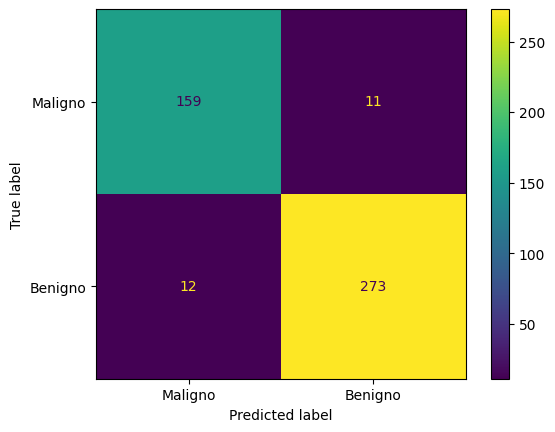

In [ ]:
# Exemplo: uso de Bagging e GridSearch()
# Carregando a base de dados
X,y=load_breast_cancer(return_X_y=True)

# Definindo classificadores de base (estimators)
dt =  DecisionTreeClassifier(criterion='entropy')
knn = KNeighborsClassifier(n_neighbors=3, weights='distance')

# Instanciando o Bagging
bg = BaggingClassifier(random_state=42)

# Caso queira usar Gridsearch, segue exemplo
# Retirando 20% da base para o GridSearch
X, X_val, y, y_val = train_test_split(X,y,test_size=.2, random_state=42, stratify=y)
# Obs: há mais hiperparâmetros do Bagging que poderiam ser explorados neste caso, segue exemplo abaixo:
bag_param = [{'estimator': [dt, knn],'n_estimators': [10, 30], 'max_samples': [0.5, 0.7, 1.0]}]
clf = GridSearchCV(bg, bag_param, scoring = 'accuracy', cv=5)

# Usando validação cruzada com T=5 folds
result=model_selection.cross_val_score(clf, X, y, cv=5)
print("Acurácia média: %.3f" % result.mean())
print("Desvio padrão: %.3f" % result.std())

# Calculando a predição para cada exempolo de teste
y_pred=model_selection.cross_val_predict(clf, X, y, cv=5)

# Calcular f1 score
f1=f1_score(y, y_pred, average='macro')
print("f1: %.3f" % f1)

print("Matriz de Confusão")
matrix=confusion_matrix(y, y_pred)
#print(matrix)
disp=ConfusionMatrixDisplay(confusion_matrix=matrix,display_labels=['Maligno', 'Benigno'])
disp.plot()




Acurácia média: 0.956
Desvio padrão: 0.017
f1: 0.953
Matriz de Confusão


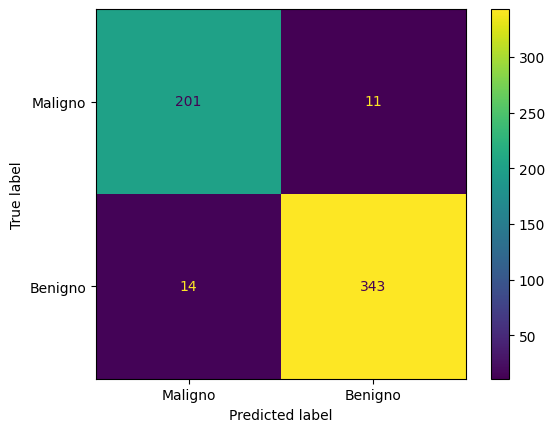

In [ ]:
# Exemplo de outros Algoritmos de ensembles homogêneos (AdaBoost, XGBoost e Random Forest).
# Agora sem uso do GridSearch. Dá para usar GridSearch claro, mas aqui optamos por nao.
# Carregando a base de dados
X,y=load_breast_cancer(return_X_y=True)

# Instanciado a técnica escolhida
# clf = AdaBoostClassifier(n_estimators=100, random_state=42)
xgboost = xgb.XGBClassifier(objective="binary:logistic", random_state=42)
#rf = RandomForestClassifier(n_estimators=100, random_state=42)

# Usando validação cruzada com T=5 folds
result=model_selection.cross_val_score(clf, X, y, cv=5)
print("Acurácia média: %.3f" % result.mean())
print("Desvio padrão: %.3f" % result.std())

# Calculando a predição para cada exempolo de teste
y_pred=model_selection.cross_val_predict(clf, X, y, cv=5)

# Calcular f1 score
f1=f1_score(y, y_pred, average='macro')
print("f1: %.3f" % f1)

print("Matriz de Confusão")
matrix=confusion_matrix(y, y_pred)
#print(matrix)
disp=ConfusionMatrixDisplay(confusion_matrix=matrix,display_labels=['Maligno', 'Benigno'])
disp.plot()



